In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Run the following commands for generating the data of Figure 13. A cycle is one execution of the while-loop of the post-processing (Algorithm 1 of the paper), i.e. one flip of the 1-line with the largest overlap with the correction. MWPM refers to the GSM decoder.

```bash
python simulations/code_capacity/post_processing_cycles.py --decoder gsm --distances 7 11 15 19 23 27 31 35 39 --error-rates 0.1 0.21 0.05 --shots 50000 --output simulations/code_capacity/Fig-13-PP-cycles/data/gsm.csv
python simulations/code_capacity/post_processing_cycles.py --decoder ism --distances 7 11 15 19 23 27 31 35 39 --error-rates 0.1 0.21 0.05 --shots 50000 --output simulations/code_capacity/Fig-13-PP-cycles/data/ism.csv
```

In [2]:
# import data from csv file
data_GSM = pd.read_csv(Path("./data") / "gsm.csv")
data_ISM = pd.read_csv(Path("./data") / "ism.csv")

# decoder configurations, MWPM refers to the GSM decoder
data = {"MWPM": data_GSM, "ISM": data_ISM}

# Figure 13:
Average number of post-processing cycles needed for convergence vs. code distance.

In [3]:
ERROR_RATES = [0.1, 0.15, 0.2]
MARKERS = {0.1: 'o', 0.15: 'D', 0.2: 's'}
LINESTYLES = {"MWPM": 'solid', "ISM": 'dotted'}

def plot_pp_cycles(data, ax, save_path=None):
    # one line per (error rate, decoder), in the order of the legend
    for p in ERROR_RATES:
        for label, df in data.items():
            sub = df[np.isclose(df['p_phys'], p)].sort_values('distance')
            ax.plot(sub['distance'], sub['num_cycles'], label=f'{label}, p={p}', marker=MARKERS[p],
                    linestyle=LINESTYLES[label], linewidth=4, markersize=12)

    ax.legend(loc='center right', prop={'size': 28})
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    plt.xlabel('Code distance d', size=28)
    plt.ylabel('Number of cycles', size=28)
    # Thicker box around plot (spines)
    for spine in ax.spines.values():
        spine.set_linewidth(3)  # Adjust thickness as needed
    # Thicker major ticks
    ax.tick_params(axis='both', which='major', width=3, length=12)  # length is optional
    # Thicker minor ticks
    ax.tick_params(axis='both', which='minor', width=1.5, length=8)  # Adjust as needed
    if save_path is not None:
        ax.figure.savefig(save_path, format='pdf', bbox_inches='tight')
    plt.show()

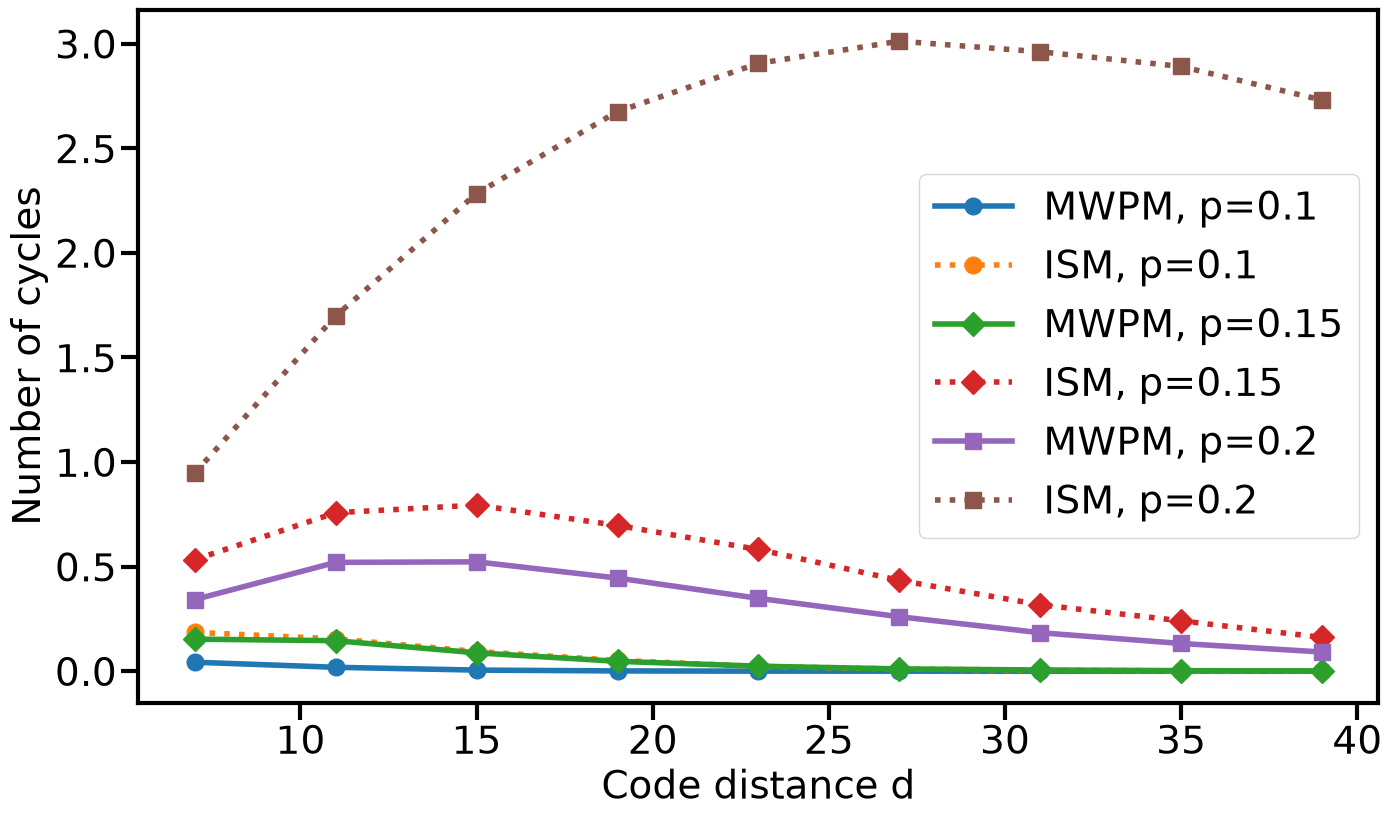

In [4]:
fig, ax = plt.subplots(figsize=(16, 9))
plot_pp_cycles(data, ax, save_path='Fig-13.pdf')